In [ ]:
import pandas as pd

df = pd.read_json("/net/projects/chai-lab/julia-shared/data/arora_data_filtered_by_protest_keywords.jsonl", lines=True)

df.head()

In [3]:
print(df.columns)

Index(['text-topic', 'text-topic-exp', 'text-entity-name',
       'text-entity-gender', 'text-entity-sentiment',
       'text-entity-sentiment-exp', 'text-generic-frame',
       'text-generic-frame-exp', 'text-issue-frame', 'text-issue-frame-exp',
       'uuid', 'title', 'img-generic-frame', 'img-frame-exp',
       'img-entity-name', 'img-entity-gender', 'img-entity-sentiment',
       'img-entity-sentiment-exp', 'image-url', 'gpt-topic', 'authors',
       'date_publish', 'description', 'language', 'maintext', 'source_domain',
       'url', 'political_leaning', 'month'],
      dtype='object')


df column notes:
    text-generic frame: no relative importance
    entity-sentiment: detected by LLM or VLM as main entity in article or image
    issue-frame: model generates outputs (limited to a few words). Original dataset has 56k + unique issue frames
    general frame: from a preset list
    title: headline
    


# Making a new column for detecting keyword matches

In [ ]:

import re

protest_keywords = [
    'protest.*?', 'strikes?', 'boycott.*?', 'walkouts?', 'walk-outs?', 'sitins?', 'sit-ins?', 'rally',
    'unrest', 'uprisings?', 'rebellions?', 'civil disobedience', 'riot.*?', 'marches',
    'demonstrations?', 'demonstrators?', 'curfews?', 'picket.*?', 'mobs?'
]

# Combine into one big regex
pattern = r"\b(" + "|".join(protest_keywords) + r")\b"

# Compile once for efficiency
protest_regex = re.compile(pattern, flags=re.IGNORECASE)

df["keyword_matches"] = df["maintext"].str.findall(protest_regex)

#df["unique_matches"] = df["article_text"].str.findall(pattern).apply(lambda x: list(set(x)))

df.head()



In [6]:
df['keyword_matches'].value_counts()

keyword_matches
[strike]                                                                                                                                                                                                                                                                                                                    5462
[rally]                                                                                                                                                                                                                                                                                                                     3825
[strikes]                                                                                                                                                                                                                                                                                                                   2828
[protest]            

## Using Spacy's pre-trained models for NER to group article entities

In [6]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "tagger"])  # only use NER

texts = df["text-entity-name"].fillna("").astype(str).tolist()

entity_labels = []
for doc in nlp.pipe(texts, batch_size=1000):
    if doc.ents:
        entity_labels.append(doc.ents[0].label_)
    else:
        entity_labels.append("UNKNOWN")

df["entity_type"] = entity_labels

df['entity_type'].head()


/home/jjzhao/protests_chai/venv/lib/python3.10/site-packages/spacy/pipeline/lemmatizer.py:188: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)


0       NORP
1     PERSON
2        FAC
3        ORG
4    UNKNOWN
Name: entity_type, dtype: object

In [7]:
#re-coding to make values lowercase
df["img-entity-sentiment"] = df["img-entity-sentiment"].str.lower()
df["text-entity-sentiment"] = df["text-entity-sentiment"].str.lower()

pd.crosstab(df['political_leaning'], df['img-entity-sentiment'])


img-entity-sentiment,mixed,negative,neutral,none,positive
political_leaning,,,,,
center,0,831,5288,37,2684
left,0,428,1461,3,667
left_lean,1,3055,12786,59,7001
right,1,1378,5751,32,2178
right_lean,0,722,2556,9,1280


# Done with preprocessing dataframe and adding columns; saving dataset as JSONL. 

In [ ]:
df.to_json("processed_df.jsonl", orient="records", lines=True)

In [2]:
import pandas as pd 
df = pd.read_json("processed_df.jsonl", lines=True)
df.head()

,text-topic,text-topic-exp,text-entity-name,text-entity-gender,text-entity-sentiment,text-entity-sentiment-exp,text-generic-frame,text-generic-frame-exp,text-issue-frame,text-issue-frame-exp,...,date_publish,description,language,maintext,source_domain,url,political_leaning,month,keyword_matches,entity_type
0,South China Sea Dispute,The article discusses a confrontation between ...,Philippine military,None,negative,The article describes the Philippine military ...,"[Security and defense, Legality, constitutiona...",The article discusses a tense confrontation be...,Geopolitical Tension,The article discusses a tense confrontation be...,...,2023-08-06 00:10:52,The Philippine military on Sunday condemned a ...,en,"MANILA, Philippines — The Philippine military ...",www.washingtontimes.com,https://www.washingtontimes.com/news/2023/aug/...,right_lean,2023-08-01_2023-08-31,[protests],NORP
1,Baseball Fight,The article is about a physical altercation be...,Jose Ramirez,male,positive,Ramirez is portrayed in a positive light as he...,"[Crime and punishment, Security and defense]",The article describes a physical altercation b...,Sports Rivalry,The article describes a physical altercation b...,...,2023-08-06 11:40:10,Chicago White Sox shortstop Tim Anderson and C...,en,Cleveland Guardians' Jose Ramírez (11) and Chi...,www.forbes.com,https://www.forbes.com/sites/berniepleskoff/20...,center,2023-08-01_2023-08-31,"[strike, rally]",PERSON
2,Climate Crisis Impact on Global Trade,The article discusses the impact of a lengthy ...,Panama Canal,None,negative,"The article discusses delays, queues, and rest...","[Economic, Capacity and resources, Climate and...",The article discusses the financial implicatio...,Climate Crisis Impact on Global Trade,The article discusses the impact of a lengthy ...,...,2023-08-14 17:10:25,Number of vessels able to pass through each da...,en,Commercial ships are facing long queues and de...,www.theguardian.com,https://www.theguardian.com/business/2023/aug/...,left_lean,2023-08-01_2023-08-31,[demonstration],FAC
3,Politics,"The article discusses political events, polici...",GOP,None,negative,The article portrays the GOP as being associat...,"[Morality, Fairness and equality, Legality, co...",The article discusses the moral implications o...,Racist Agenda,The article frames the modern Republican Party...,...,2023-08-07 13:30:00,"Senator Scott, please do the right thing.",en,"It pains me to say this, but today’s GOP is th...",thehill.com,https://thehill.com/opinion/columnists/juan-wi...,center,2023-08-01_2023-08-31,[protest],ORG
4,Healthcare Rights,The article discusses the case of two women wh...,Ugandan authorities,None,negative,The article discusses two women who were detai...,"[Economic, Legality, constitutionality and jur...",The article discusses the financial implicatio...,Human Rights Violation,The article discusses the detention of two wom...,...,2023-08-22 06:00:37,Two cases to be heard this month could serve a...,en,Two women who were prevented from leaving hosp...,www.theguardian.com,https://www.theguardian.com/global-development...,left_lean,2023-08-01_2023-08-31,"[Protestant, protestant]",UNKNOWN


In [3]:
import matplotlib.pyplot as plt

subset = df[df['text-entity-sentiment'].isin(['negative', 'positive', 'neutral', 'none', 'mixed'])]

#column-wise (sum to 1) relative frequency crosstab
ct = pd.crosstab(subset['political_leaning'], subset['text-entity-sentiment'], normalize='columns').round(2)
print(ct)





text-entity-sentiment  mixed  negative  neutral  none  positive
political_leaning                                              
center                  0.23      0.14     0.19  0.04      0.24
left                    0.04      0.07     0.04  0.01      0.04
left_lean               0.45      0.41     0.52  0.90      0.48
right                   0.18      0.26     0.18  0.04      0.15
right_lean              0.11      0.12     0.08  0.01      0.08


Preliminary crosstab between political leaning of the news source and sentiment towards the VLM/LLM-detected main entity in the text. Columns sum to 1. We observe that the distribution of political leanings for all "negative" sentiments is more or less the same as "positive". 

I suspected that perhaps we'd see a higher proportion of "negative" sentiment articles be right-leaning, assuming the main entity is often protesters and lobbyists. 

In [15]:
print(df['text-entity-name'].value_counts())

text-entity-name
Donald Trump            2110
Israel                   457
Ron DeSantis             393
Hamas                    382
President Biden          380
                        ... 
Touch-a-Truck event        1
Gail Maddox                1
Georgian Dream party       1
Travis Scott               1
Manufacturers              1
Name: count, Length: 19971, dtype: int64


## Fighting Words initial exploration

In [9]:
from fighting_words import bayes_compare_language

df['maintext'] = df['maintext'].str.lower()
neg_set = df[df['text-entity-sentiment'] == 'negative']
pos_set = df[df['text-entity-sentiment'] == 'positive']

l1_series = neg_set['maintext']
l2_series = pos_set['maintext']

trimmed_l1 = l1_series.tolist()[:12]
trimmed_l2 = l2_series.tolist()[:12]

# Convert to list first:
result = bayes_compare_language(l1_series.tolist(), l2_series.tolist())

Vocab size is 15000
Comparing language...


In [ ]:
print(result[-10:])

# compare left vs right, visualizations

# "what are words most associated with ___ protests?"
# one vs. rest, depends on how I define l1 and l2 
# use EDA to determine list of categories/frames
# put thoughts in gdoc instead

#next week, align on "here are the PP literature questions we're interested in"


[('government', np.float64(50.31466800147603)), ('court', np.float64(50.58280134719547)), ('hamas', np.float64(50.895516230003004)), ('killed', np.float64(51.381647936398885)), ('attack', np.float64(53.31454365086819)), ('israeli', np.float64(53.74415189003158)), ('gaza', np.float64(54.04817295951145)), ('israel', np.float64(57.70538557443433)), ('trump', np.float64(69.73302675474577)), ('police', np.float64(74.87436030991854))]


most positive z-scores would be most negative sentiment

- Named Entity Recognition (NER): can we group the entity names themselves, for "protesters" or "public figures"? currently many unique vals

determine if fightingwords is viable. 
look across dimensions, write up interp. start to connect to protest literature



In [4]:
df['political_leaning'].value_counts()

political_leaning
left_lean     23601
right         10182
center         9120
right_lean     4633
left           2702
Name: count, dtype: int64

Vocab size is 15000
Comparing language...


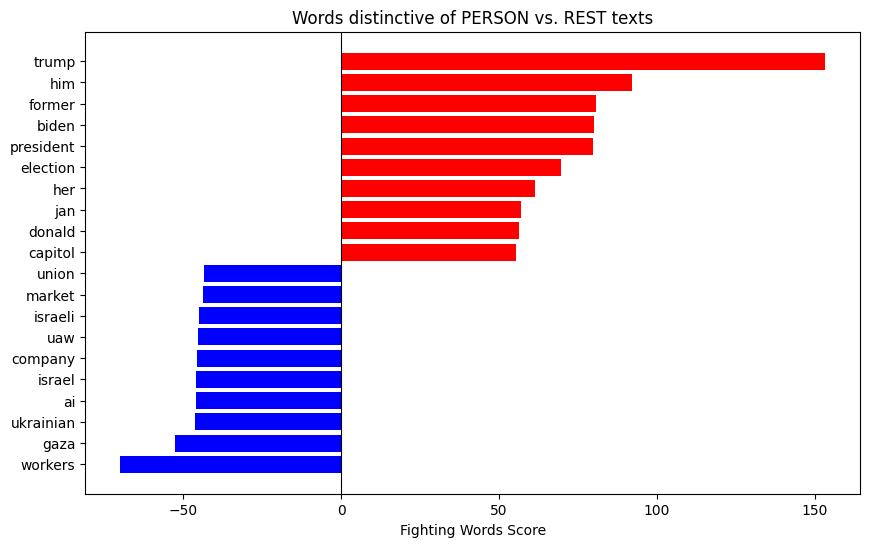

In [ ]:
from fighting_words import bayes_compare_language

df['maintext'] = df['maintext'].str.lower()
one_set = df[df['entity_type'] == 'PERSON']
rest_set = df[df['entity_type'] != 'PERSON']

l1_series = one_set['maintext']
l2_series = rest_set['maintext']


result = bayes_compare_language(l1_series.tolist(), l2_series.tolist())

import matplotlib.pyplot as plt

# Take top 10 from each side
left_terms = result[:10]
right_terms = result[-10:]

# Prepare for plotting
words = [w for w, s in left_terms] + [w for w, s in right_terms]
scores = [s for w, s in left_terms] + [s for w, s in right_terms]
colors = ["blue"] * len(left_terms) + ["red"] * len(right_terms)

plt.figure(figsize=(10,6))
plt.barh(words, scores, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Fighting Words Score")
plt.title("Words distinctive of PERSON vs. REST texts")
plt.show()


Vocab size is 15000
Comparing language...


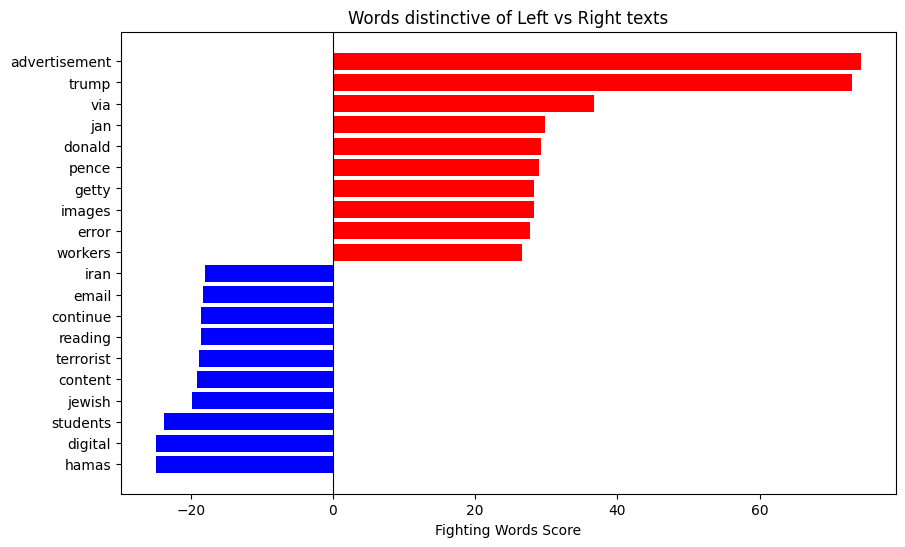

In [3]:
from fighting_words import bayes_compare_language

df['maintext'] = df['maintext'].str.lower()
left_set = df[df['political_leaning'] == 'left']
right_set = df[df['political_leaning'] == 'right']

l1_series = left_set['maintext']
l2_series = right_set['maintext']

trimmed_l1 = l1_series.tolist()[:12]
trimmed_l2 = l2_series.tolist()[:12]

# Convert to list first:
result = bayes_compare_language(l1_series.tolist(), l2_series.tolist())

import matplotlib.pyplot as plt

# Take top 10 from each side
left_terms = result[:10]
right_terms = result[-10:]

# Prepare for plotting
words = [w for w, s in left_terms] + [w for w, s in right_terms]
scores = [s for w, s in left_terms] + [s for w, s in right_terms]
colors = ["blue"] * len(left_terms) + ["red"] * len(right_terms)

plt.figure(figsize=(10,6))
plt.barh(words, scores, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Fighting Words Score")
plt.title("Words distinctive of Left vs Right texts")
plt.show()
